### Explorando os dados

In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.cluster import KMeans
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
)

SEED = 77

In [100]:
BASE_URL = 'https://raw.githubusercontent.com/AdaLimana/pos-ia/refs/heads/main/poc-02/'
DATASET_1MIN = 'lag-e-throughput-1min.csv' 
DATASET_5MIN = 'lag-e-throughput-5min.csv' 
DATASET_1H = 'lag-e-throughput-1h.csv' 

In [101]:
df_5min = pd.read_csv(BASE_URL + DATASET_5MIN, sep=';', parse_dates=['timestamp'], index_col='timestamp').sort_index()
df_1min = pd.read_csv(BASE_URL + DATASET_1MIN, sep=';', parse_dates=['timestamp'], index_col='timestamp').sort_index()
df = pd.read_csv(BASE_URL + DATASET_1H, sep=';', parse_dates=['timestamp'], index_col='timestamp').sort_index()


print('Dados carregados com sucesso!')

Dados carregados com sucesso!


In [102]:
print(f'Coletas a cada 1h: {df.shape[0]} registros, de {df.index[0]} a {df.index[-1]}')
print()
df.info()

Coletas a cada 1h: 40494 registros, de 2025-10-22 03:00:00+00:00 a 2026-10-23 02:00:00+00:00

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 40494 entries, 2025-10-22 03:00:00+00:00 to 2026-10-23 02:00:00+00:00
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   throughput     40494 non-null  float64
 1   lag            40489 non-null  float64
 2   consumerGroup  40494 non-null  object 
 3   topic          40494 non-null  object 
dtypes: float64(2), object(2)
memory usage: 1.5+ MB


In [103]:
print(f'Coletas a cada 5min: {df_5min.shape[0]} registros, de {df_5min.index[0]} a {df_5min.index[-1]}')
print()
df_5min.info()

Coletas a cada 5min: 92165 registros, de 2026-08-20 02:55:00+00:00 a 2026-10-23 02:55:00+00:00

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 92165 entries, 2026-08-20 02:55:00+00:00 to 2026-10-23 02:55:00+00:00
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   throughput     92165 non-null  float64
 1   lag            91954 non-null  float64
 2   consumerGroup  92165 non-null  object 
 3   topic          92165 non-null  object 
dtypes: float64(2), object(2)
memory usage: 3.5+ MB


In [104]:
print(f'Coletas a cada 1min: {df_1min.shape[0]} registros, de {df_1min.index[0]} a {df_1min.index[-1]}')
print()
df_1min.info()

Coletas a cada 1min: 172799 registros, de 2026-09-29 02:59:00+00:00 a 2026-10-23 02:58:00+00:00

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 172799 entries, 2026-09-29 02:59:00+00:00 to 2026-10-23 02:58:00+00:00
Data columns (total 4 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   throughput     172799 non-null  float64
 1   lag            158355 non-null  float64
 2   consumerGroup  172799 non-null  object 
 3   topic          172799 non-null  object 
dtypes: float64(2), object(2)
memory usage: 6.6+ MB


Valores faltantes por par de consumer x tópico

In [105]:
print('Coletas a cada 1h')
df['lag'].isna().groupby(by=[df['topic'], df['consumerGroup']]).sum().reset_index()

Coletas a cada 1h


,topic,consumerGroup,lag
0,topic-a,consumer-d,0
1,topic-b,consumer-a,0
2,topic-c,consumer-a,0
3,topic-c,consumer-b,5
4,topic-c,consumer-c,0


In [106]:
print('Coletas a cada 5min')
df_5min['lag'].isna().groupby(by=[df_5min['topic'], df_5min['consumerGroup']]).sum().reset_index()

Coletas a cada 5min


,topic,consumerGroup,lag
0,topic-a,consumer-d,0
1,topic-b,consumer-a,0
2,topic-c,consumer-a,0
3,topic-c,consumer-b,211
4,topic-c,consumer-c,0


In [107]:
print('Coletas a cada 1min')
df_1min['lag'].isna().groupby(by=[df_1min['topic'], df_1min['consumerGroup']]).sum().reset_index()

Coletas a cada 1min


,topic,consumerGroup,lag
0,topic-a,consumer-d,0
1,topic-b,consumer-a,200
2,topic-c,consumer-a,204
3,topic-c,consumer-b,13967
4,topic-c,consumer-c,73


In [108]:
start = '2026-09-29'
end = '2026-10-01' 
topic = 'topic-b'
consumer_group = 'consumer-a'
apply_log = False

serie_lag = df[(df['topic'] == topic) & (df['consumerGroup'] == consumer_group)][start:end]['lag']
serie_throughput = df[(df['topic'] == topic) & (df['consumerGroup'] == consumer_group)][start:end]['throughput']

serie_lag_5min = df_5min[(df_5min['topic'] == topic) & (df_5min['consumerGroup'] == consumer_group)][start:end]['lag']
serie_throughput_5min = df_5min[(df_5min['topic'] == topic) & (df_5min['consumerGroup'] == consumer_group)][start:end]['throughput']

serie_lag_1min = df_1min[(df_1min['topic'] == topic) & (df_1min['consumerGroup'] == consumer_group)][start:end]['lag']
serie_throughput_1min = df_1min[(df_1min['topic'] == topic) & (df_1min['consumerGroup'] == consumer_group)][start:end]['throughput']

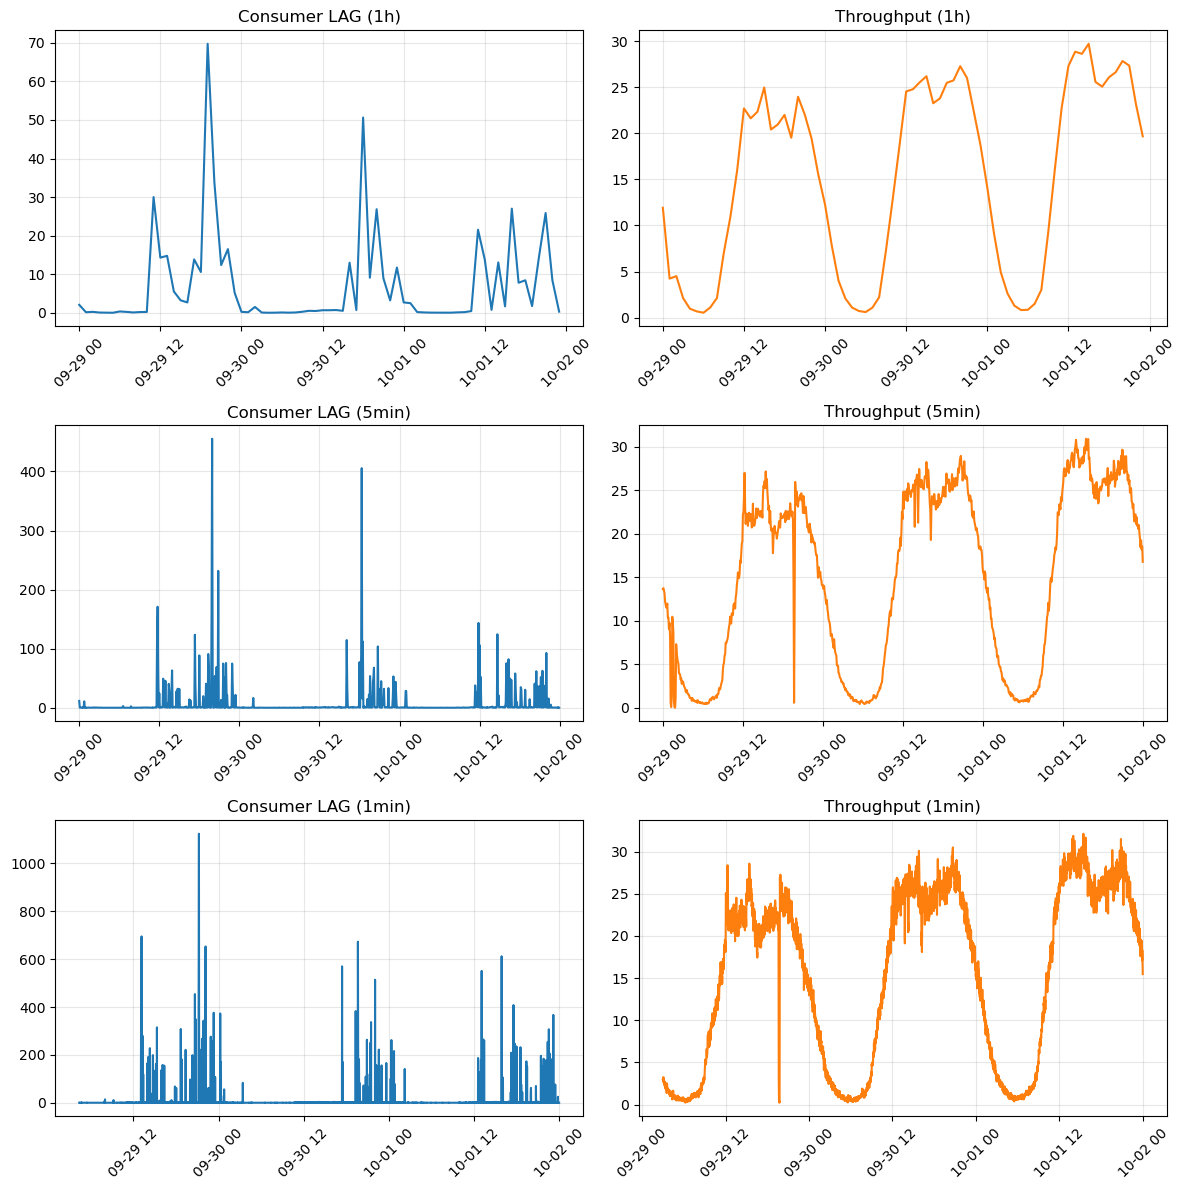

In [109]:

fig, eixos = plt.subplots(3, 2, figsize=(12, 12))
eixos[0,0].plot(serie_lag)
eixos[0,0].set_title('Consumer LAG (1h)')
eixos[0,0].tick_params(axis='x', labelrotation=45)
if apply_log: eixos[0,0].set_yscale('symlog', linthresh=10)

eixos[0,1].plot(serie_throughput, color='tab:orange')
eixos[0,1].set_title('Throughput (1h)')
eixos[0,1].tick_params(axis='x', labelrotation=45)
if apply_log: eixos[0,1].set_yscale('symlog', linthresh=10)

eixos[1,0].plot(serie_lag_5min)
eixos[1,0].set_title('Consumer LAG (5min)')
eixos[1,0].tick_params(axis='x', labelrotation=45)
if apply_log: eixos[1,0].set_yscale('symlog', linthresh=10)

eixos[1,1].plot(serie_throughput_5min, color='tab:orange')
eixos[1,1].set_title('Throughput (5min)')
eixos[1,1].tick_params(axis='x', labelrotation=45)
if apply_log: eixos[1,1].set_yscale('symlog', linthresh=10)

eixos[2,0].plot(serie_lag_1min)
eixos[2,0].set_title('Consumer LAG (1min)')
eixos[2,0].tick_params(axis='x', labelrotation=45)
if apply_log: eixos[2,0].set_yscale('symlog', linthresh=10)

eixos[2,1].plot(serie_throughput_1min, color='tab:orange')
eixos[2,1].set_title('Throughput (1min)')
eixos[2,1].tick_params(axis='x', labelrotation=45)
if apply_log: eixos[2,1].set_yscale('symlog', linthresh=10)

for line in eixos:
    for column in line:
        column.grid(alpha=0.3)

plt.tight_layout()
plt.show()

O problema de usar o histórico da média de lag a cada hora tem relação com o fato que ao analisar o lag em dado intervalo estarmos usando o lag real daquele momento?

Seria possível contornar esse problema se usassemos a média da última hora em vez do lag no dado momento?

Ideia para identificação se o lag do dado momento é uma anomalia ou não:
- A cada 15min, coletar o lag e throughtput da última hora
- Fazer a média do lag e throughput coletado.
- Considerar o valor menor entre média e valor atual
- Validar

### Explorando os modelos

In [110]:
REFERENCE_COLUMN = 'lag'
CONTAMINATION_RATE = 0.1

def plotar_anomalias(dados, anomalias, label, apply_log=False):
    fig, eixos = plt.subplots(1, 2, figsize=(16, 4))
    eixos[0].plot(dados.index, dados['lag'], label='Normal')
    eixos[0].scatter(anomalias.index, anomalias['lag'], s=18, color='tab:red', label='Anomalia')
    eixos[0].set_title(f'Anomalias Lag - {label}')
    eixos[0].tick_params(axis='x', labelrotation=45)
    if apply_log: eixos[0].set_yscale('symlog', linthresh=10)

    eixos[1].plot(dados.index, dados['throughput'], label='Normal')
    eixos[1].scatter(anomalias.index, anomalias['throughput'], s=18, color='tab:red', label='Anomalia')
    eixos[1].set_title(f'Anomalias Throughput - {label}')
    eixos[1].tick_params(axis='x', labelrotation=45)
    if apply_log: eixos[1].set_yscale('symlog', linthresh=10)

    for column in eixos:
        column.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

#### Separação dados para análise

In [111]:
df_filtered = df[(df['topic'] == topic) & (df['consumerGroup'] == consumer_group)]

training = df_filtered[:'2026-08-23']
test = df_filtered['2026-08-23':]


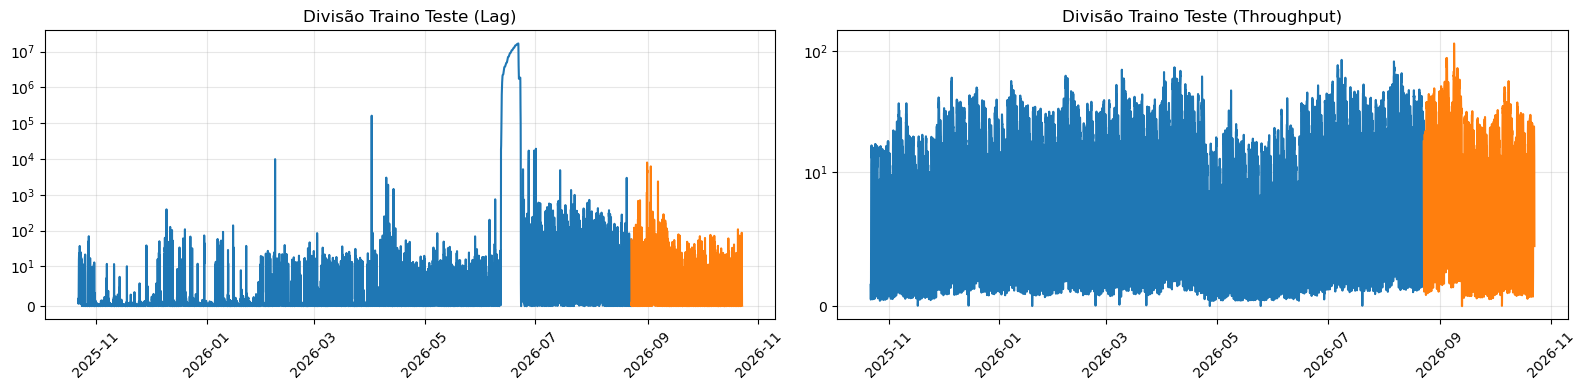

In [112]:
fig, eixos = plt.subplots(1, 2, figsize=(16, 4))
eixos[0].plot(training.index, training['lag'], label='Treino')
eixos[0].plot(test.index, test['lag'], label='Teste')
eixos[0].set_title('Divisão Traino Teste (Lag)')
eixos[0].tick_params(axis='x', labelrotation=45)
eixos[0].set_yscale('symlog', linthresh=10)

eixos[1].plot(training.index, training['throughput'], label='Treino')
eixos[1].plot(test.index, test['throughput'], label='Teste')
eixos[1].set_title('Divisão Traino Teste (Throughput)')
eixos[1].tick_params(axis='x', labelrotation=45)
eixos[1].set_yscale('symlog', linthresh=10)

for column in eixos:
    column.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Z-Score

Quantidade de outliers pelo critério de Z-Score (|Z| > 3): 0


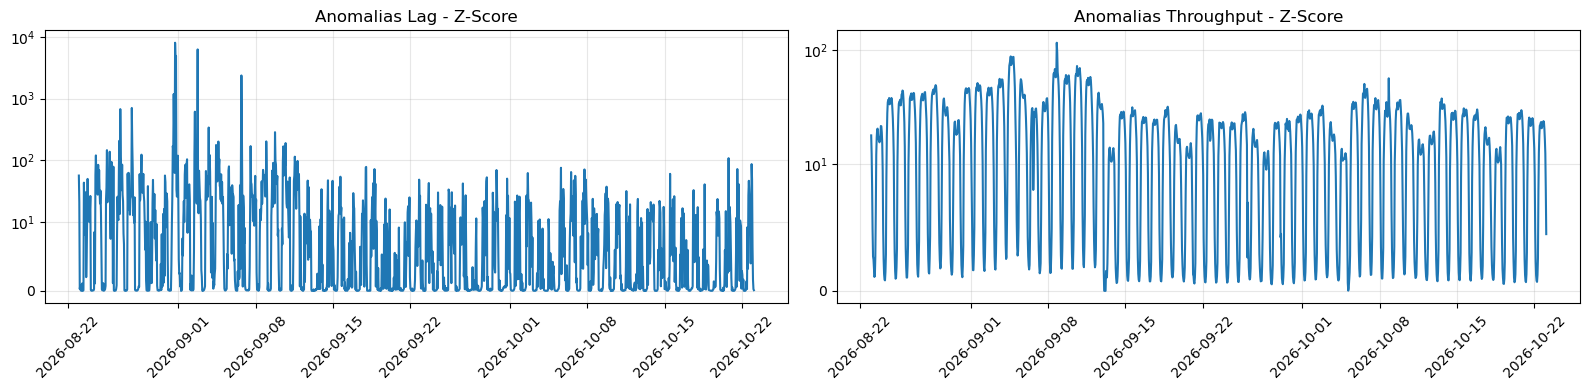

In [113]:
# z_scores = stats.zscore(training['lag'], nan_policy='omit')
z_scores = (test['lag'] - training[REFERENCE_COLUMN].mean()) / training[REFERENCE_COLUMN].std()

# np.abs(z_scores) > 3 -> True para cada valor a mais de 3 desvios-padrão da média
outliers_zscore = test[np.abs(z_scores) > 3]
print(f"Quantidade de outliers pelo critério de Z-Score (|Z| > 3): {len(outliers_zscore)}")

plotar_anomalias(test, outliers_zscore, 'Z-Score', apply_log=True)


#### IQR

Q1 = 0.2 | Q3 = 8.3 | IQR = 8.1
Limite inferior = -11.9 | Limite superior = 20.4

Quantidade de outliers pela regra do IQR: 288


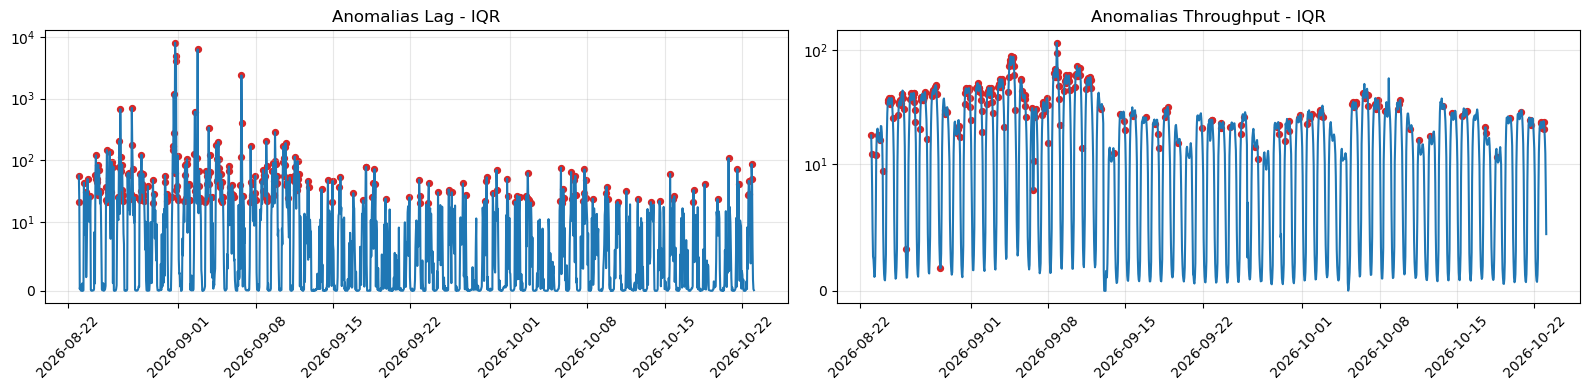

In [114]:
Q1 = training[REFERENCE_COLUMN].quantile(0.25)
Q3 = training[REFERENCE_COLUMN].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f'Q1 = {Q1:.1f} | Q3 = {Q3:.1f} | IQR = {IQR:.1f}')
print(f'Limite inferior = {limite_inferior:.1f} | Limite superior = {limite_superior:.1f}')

outliers_iqr = test[
    (test[REFERENCE_COLUMN] < limite_inferior) |
    (test[REFERENCE_COLUMN] > limite_superior)
]

print(f'\nQuantidade de outliers pela regra do IQR: {len(outliers_iqr)}')

plotar_anomalias(test, outliers_iqr, 'IQR', apply_log=True)

#### Isolation Forest

Anomalias encontradas pelo Isolation Forest: 126 de 1467


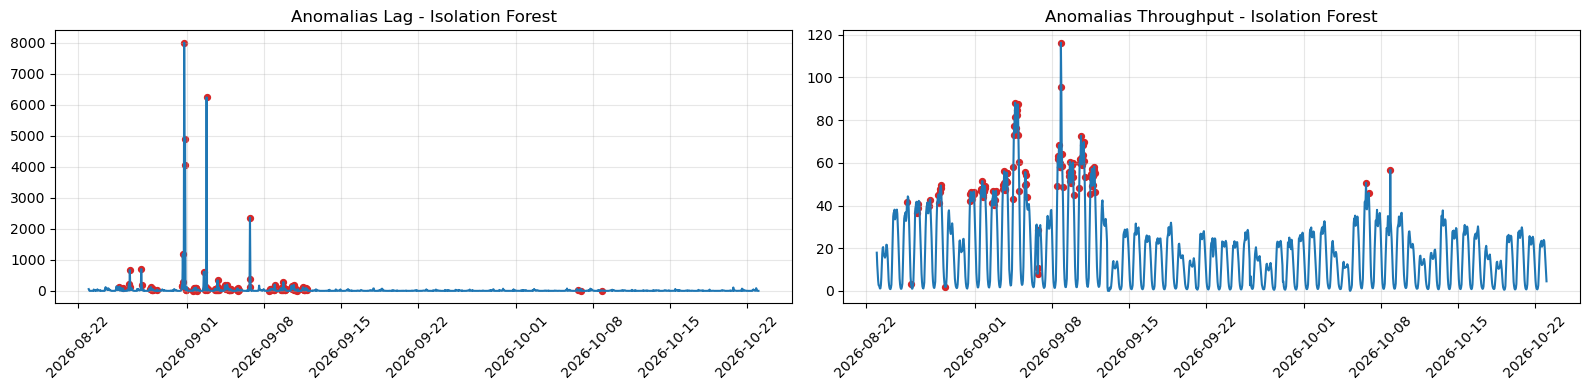

Identificados como anomalias


,throughput,lag,consumerGroup,topic
timestamp,,,,
2026-08-25 19:00:00+00:00,41.42,137.98,consumer-a,topic-b
2026-08-26 03:00:00+00:00,3.33,78.98,consumer-a,topic-b
2026-08-26 16:00:00+00:00,36.58,207.92,consumer-a,topic-b
2026-08-26 18:00:00+00:00,38.85,674.79,consumer-a,topic-b
2026-08-26 19:00:00+00:00,40.72,115.29,consumer-a,topic-b
...,...,...,...,...
2026-09-11 21:00:00+00:00,55.02,40.00,consumer-a,topic-b
2026-09-11 22:00:00+00:00,46.19,60.19,consumer-a,topic-b
2026-10-06 15:00:00+00:00,50.60,14.88,consumer-a,topic-b


In [115]:
pipeline_isolation_forest = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector", IsolationForest(contamination=CONTAMINATION_RATE, random_state=SEED)),
])
pipeline_isolation_forest.fit(training[['lag', 'throughput']])

flag_isolation_forest = (pipeline_isolation_forest.predict(test[['lag', 'throughput']]) == -1).astype(int)
score_isolation_forest = -pipeline_isolation_forest.decision_function(test[['lag', 'throughput']])

print(f"Anomalias encontradas pelo Isolation Forest: {flag_isolation_forest.sum()} de {len(flag_isolation_forest)}")

plotar_anomalias(test, test[flag_isolation_forest==1], "Isolation Forest")

print("Identificados como anomalias")
display(test[flag_isolation_forest==1])

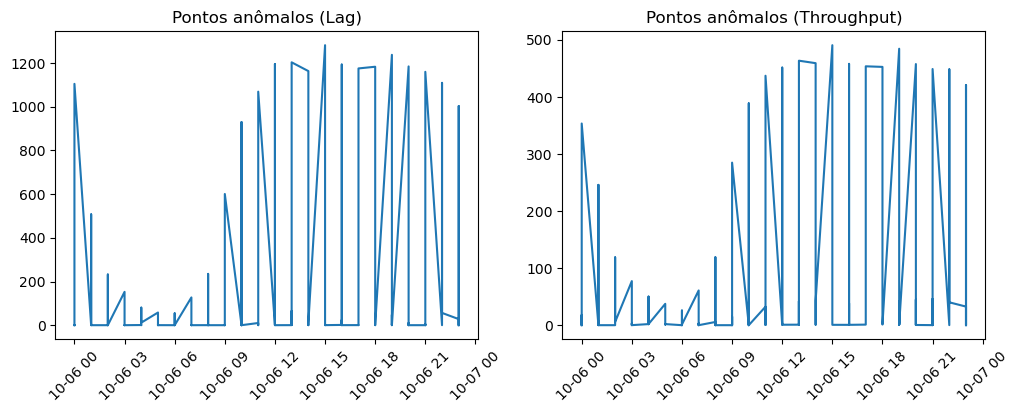

In [116]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(df.loc['2026-10-06'].index, df.loc['2026-10-06']['lag'])
eixos[0].set_title('Pontos anômalos (Lag)')
eixos[0].tick_params(axis='x', labelrotation=45)
# eixos[0].set_yscale('symlog', linthresh=10)

eixos[1].plot(df.loc['2026-10-06'].index, df.loc['2026-10-06']['throughput'])
eixos[1].set_title('Pontos anômalos (Throughput)')
eixos[1].tick_params(axis='x', labelrotation=45)
# eixos[1].set_yscale('symlog', linthresh=10)

#### One-Class SVM

Anomalias encontradas pelo One-Class SVM: 129 de 1467


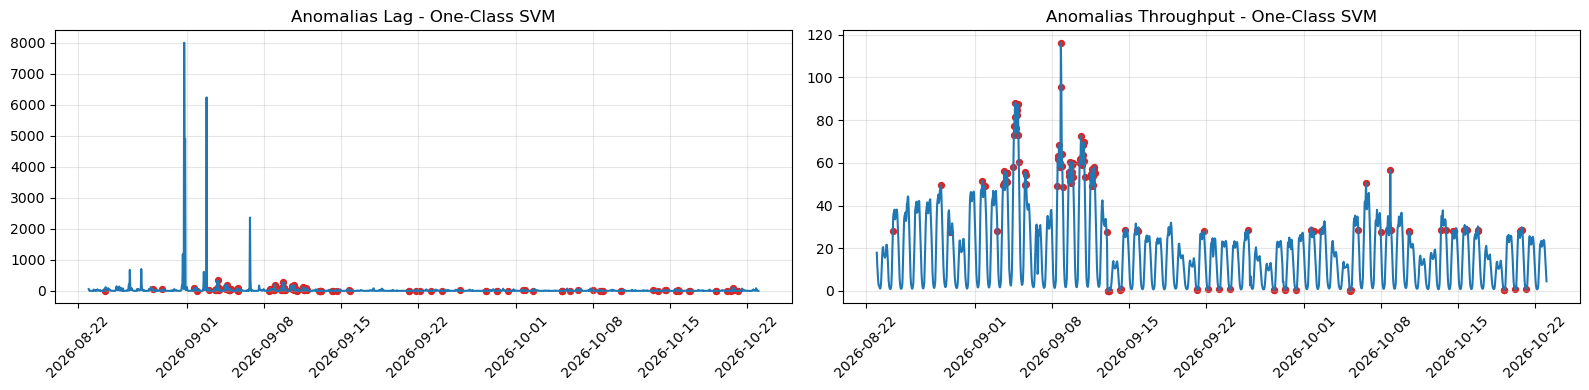

Identificados como anomalias


,throughput,lag,consumerGroup,topic
timestamp,,,,
2026-08-24 11:00:00+00:00,28.07,1.08,consumer-a,topic-b
2026-08-28 20:00:00+00:00,49.39,60.41,consumer-a,topic-b
2026-08-29 17:00:00+00:00,27.72,48.30,consumer-a,topic-b
2026-09-01 15:00:00+00:00,51.46,84.47,consumer-a,topic-b
2026-09-01 20:00:00+00:00,49.27,8.46,consumer-a,topic-b
...,...,...,...,...
2026-10-20 05:00:00+00:00,0.68,0.00,consumer-a,topic-b
2026-10-20 15:00:00+00:00,28.23,0.57,consumer-a,topic-b
2026-10-20 19:00:00+00:00,28.57,108.57,consumer-a,topic-b


In [117]:
pipeline_ocsvm = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector", OneClassSVM(nu=CONTAMINATION_RATE, kernel="rbf", gamma="scale")),
])
pipeline_ocsvm.fit(training[['lag', 'throughput']])

flag_ocsvm = (pipeline_ocsvm.predict(test[['lag', 'throughput']]) == -1).astype(int)
score_ocsvm = -pipeline_ocsvm.decision_function(test[['lag', 'throughput']])

print(f"Anomalias encontradas pelo One-Class SVM: {flag_ocsvm.sum()} de {len(flag_ocsvm)}")

plotar_anomalias(test, test[flag_ocsvm==1], "One-Class SVM")

print("Identificados como anomalias")
display(test[flag_ocsvm==1])